# MCES hexbin correlation plot

This notebook computes the Spearman correlation between molecular embedding cosine similarities and the normalized $d_{MCES^w}$ metric. \
The correlations are visualised as a relative density hexbin heatmap.

You should only need to edit the file paths section below

## Imports

In [1]:
from pathlib import Path
import math

import rdkit
from rdkit import Chem

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.colors import PowerNorm
from matplotlib.cm import ScalarMappable
from scipy.stats import spearmanr


## File paths

In [ ]:
MCES_PATH   = '/path/to/mces_distances.npz'
CENSOR_PATH = '/path/to/censor_mask.npy'


files = [
    "/path/to/Atom Pair MCES.npy",
    "/home/blake/Documents/OPIG/cheminformatics/fingerprint_project/Final experiments/ECFP4 MCES.npy",
    "/path/to/Topological Torsion MCES.npy",
    "/path/to/ChemBERTa MCES pairwise cosines.dat",
    "/path/to/CheMeleon MCES pairwise cosines.dat",
    "/path/to/COATI MCES pairwise cosines.dat",
    "/path/to/MolCLR MCES pairwise cosines.dat",
    "/path/to/MiniMol MCES pairwise cosines.dat",
    "/path/to/MolE MCES pairwise cosines.dat",
    "/path/to/UniMol MCES pairwise cosines.dat",
    "/path/to/MolFormer MCES pairwise cosines.dat",
    "/path/to/MolBERT MCES pairwise cosines.dat",
]

## Load MCES data

In [3]:
censored_arr = np.load(CENSOR_PATH)

In [4]:
distances = np.load(MCES_PATH)
censored  = (distances['mces'] == -1)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


## Pre-process MCES data

In [5]:
def molecule_mces_weight(smiles, *, remove_hs=True):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    if remove_hs:
        mol = Chem.RemoveHs(mol)

    return sum(bond.GetBondTypeAsDouble() for bond in mol.GetBonds())


def mces_denominator_flat(smiles_list, *, remove_hs=True):
    """
    Returns flat pairwise denominators W_i + W_j
    in scipy pdist order:
      (0,1), (0,2), ..., (1,2), ...
    """
    weights = np.array(
        [molecule_mces_weight(smi, remove_hs=remove_hs) for smi in smiles_list],
        dtype=float,
    )

    i, j = np.triu_indices(len(weights), k=1)
    return weights[i] + weights[j]

In [6]:
# Preprocessing. Compute MCES norm and exclude invalid molecules
mces_denom = mces_denominator_flat(smiles)
mces_norm  = np.divide(mces, mces_denom)
censored   = censored | (mces >= 10) | censored_arr
mces_norm  = mces_norm[~censored]

[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not removing hydrogen atom without neighbors
[17:05:13] WARNING: not r

## Plot relative density hexbins

In [ ]:
# ---------------------------------------------------------
# Matplotlib / seaborn settings
# ---------------------------------------------------------

# Keeps text editable in SVG/PDF.
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

sns.set_theme(style="ticks")


# ---------------------------------------------------------
# Helper functions
# ---------------------------------------------------------

def load_array(file):
    file = Path(file)

    if file.suffix == ".npy":
        return np.load(file)

    if file.suffix == ".dat":
        return np.fromfile(
            file,
            dtype=np.float32,
        )

    raise ValueError(
        f"Unsupported file type: {file.suffix}"
    )


def make_xlabel(file):
    file = Path(file)
    name = file.stem

    if file.suffix == ".dat":
        return name.split(" MCES ")[0]

    words = name.split()

    return " ".join(words[:-1])


def figure_letter(index):
    """
    Convert zero-based indices to lowercase figure labels.

    Examples
    --------
    0 -> a
    1 -> b
    25 -> z
    26 -> aa
    """
    label = ""

    while True:
        index, remainder = divmod(index, 26)

        label = (
            chr(ord("a") + remainder)
            + label
        )

        if index == 0:
            return label

        index -= 1


# ---------------------------------------------------------
# Plotting function
# ---------------------------------------------------------

def plot_grid(
    files,
    mces_norm,
    censored,
    ncols=4,
    vertical_gap=0.30,
    out_files=None,
    rasterize_hex=True,
    spearman_fontsize=14,
    tick_fontsize=12,
    label_fontsize=13,
    panel_label_start="b",
    panel_label_fontsize=18,
    panel_label_x=-0.10,
    panel_label_y=1.10,
    gridsize=30,
    density_gamma=0.5,
    colorbar_label="Relative density",
    colorbar_gap=0.045,
    colorbar_width=0.018,
):
    nrows = math.ceil(
        len(files) / ncols
    )

    # Histogram colour.
    color = "#4E86BC"

    # Hexbin colour map.
    cmap = plt.get_cmap("Blues")

    censored = np.asarray(
        censored,
        dtype=bool,
    )

    mces_norm = np.asarray(
        mces_norm
    )

    panel_label_start_index = (
        ord(panel_label_start.lower())
        - ord("a")
    )

    # -----------------------------------------------------
    # Grid layout
    # -----------------------------------------------------

    outer_nrows = (
        2 * nrows - 1
    )

    height_ratios = []

    for row in range(nrows):
        height_ratios.append(1.0)

        if row < nrows - 1:
            height_ratios.append(
                vertical_gap
            )

    fig = plt.figure(
        figsize=(
            5.0 * ncols,
            5.2 * nrows,
        )
    )

    outer = fig.add_gridspec(
        outer_nrows,
        ncols,
        height_ratios=height_ratios,
        hspace=0.0,
        wspace=0.35,
    )

    hexbin_handles = []
    joint_axes = []

    # -----------------------------------------------------
    # Plot each panel
    # -----------------------------------------------------

    for i, file in enumerate(files):

        plot_row = i // ncols
        col = i % ncols
        outer_row = 2 * plot_row

        # -------------------------------------------------
        # Load similarity values
        # -------------------------------------------------

        arr_raw = load_array(file)

        if len(arr_raw) == len(censored):
            arr = arr_raw[~censored]
        else:
            arr = arr_raw

        if len(mces_norm) == len(censored):
            y = mces_norm[~censored]
        else:
            y = mces_norm

        if len(arr) != len(y):
            raise ValueError(
                f"Length mismatch for {file}: "
                f"arr has length {len(arr)}, "
                f"y has length {len(y)}"
            )

        # Remove non-finite values if present.
        valid = (
            np.isfinite(arr)
            & np.isfinite(y)
        )

        arr = arr[valid]
        y = y[valid]

        print(
        f"{make_xlabel(file)}: "
        f"{len(arr):,} pairs plotted"
        )

        if len(arr) == 0:
            raise ValueError(
                f"No finite values available for {file}"
            )

        # -------------------------------------------------
        # Spearman correlation
        # -------------------------------------------------

        rho, pval = spearmanr(
            arr,
            y,
        )

        # -------------------------------------------------
        # Marginal + joint layout
        # -------------------------------------------------

        inner = (
            outer[
                outer_row,
                col,
            ]
            .subgridspec(
                2,
                1,
                height_ratios=(1, 4),
                hspace=0.05,
            )
        )

        ax_marg_x = fig.add_subplot(
            inner[0, 0]
        )

        ax_joint = fig.add_subplot(
            inner[1, 0],
            sharex=ax_marg_x,
        )

        joint_axes.append(
            ax_joint
        )

        # -------------------------------------------------
        # Figure lettering
        # -------------------------------------------------

        panel_label = figure_letter(
            panel_label_start_index + i
        )

        ax_marg_x.text(
            panel_label_x,
            panel_label_y,
            panel_label,
            transform=ax_marg_x.transAxes,
            ha="left",
            va="top",
            fontsize=panel_label_fontsize,
            fontweight="bold",
            clip_on=False,
        )

        # -------------------------------------------------
        # Hexbin
        # -------------------------------------------------

        hb = ax_joint.hexbin(
            arr,
            y,
            gridsize=gridsize,
            mincnt=1,
            cmap=cmap,
            linewidths=0,
        )

        hexbin_handles.append(
            hb
        )

        if rasterize_hex:
            hb.set_rasterized(
                True
            )

        # -------------------------------------------------
        # Marginal histogram
        # -------------------------------------------------

        ax_marg_x.hist(
            arr,
            bins=30,
            color=color,
            edgecolor="white",
            linewidth=0.8,
            rwidth=0.975,
        )

        ax_marg_x.set_yticks([])

        ax_marg_x.tick_params(
            axis="x",
            which="both",
            bottom=False,
            top=False,
            labelbottom=False,
        )

        ax_marg_x.tick_params(
            axis="y",
            which="both",
            left=False,
            right=False,
            labelleft=False,
        )

        ax_marg_x.set_xlabel("")
        ax_marg_x.set_ylabel("")

        for spine in (
            ax_marg_x.spines.values()
        ):
            spine.set_visible(
                False
            )

        # -------------------------------------------------
        # Spearman annotation
        # -------------------------------------------------

        ax_joint.text(
            0.95,
            0.95,
            f"ρ = {rho:.3f}",
            transform=ax_joint.transAxes,
            ha="right",
            va="top",
            fontsize=spearman_fontsize,
            bbox={
                "boxstyle": "round",
                "facecolor": "white",
                "alpha": 0.8,
                "edgecolor": "none",
            },
        )

        # -------------------------------------------------
        # Axis labels
        # -------------------------------------------------

        ax_joint.set_xlabel(
            make_xlabel(file),
            fontsize=label_fontsize,
        )

        if col == 0:
            ax_joint.set_ylabel(
                "Normalized MCES",
                fontsize=label_fontsize,
            )
        else:
            ax_joint.set_ylabel("")

        ax_joint.tick_params(
            axis="both",
            which="major",
            labelsize=tick_fontsize,
        )

        sns.despine(
            ax=ax_joint
        )

    # -----------------------------------------------------
    # Hide unused cells
    # -----------------------------------------------------

    for j in range(
        len(files),
        nrows * ncols,
    ):
        plot_row = j // ncols
        col = j % ncols
        outer_row = 2 * plot_row

        ax = fig.add_subplot(
            outer[
                outer_row,
                col,
            ]
        )

        ax.axis("off")

    # -----------------------------------------------------
    # Convert raw hexbin counts to relative density
    # -----------------------------------------------------

    for hb in hexbin_handles:

        counts = np.asarray(
            hb.get_array()
        )

        max_count = counts.max()

        relative_density = (
            counts / max_count
        )

        hb.set_array(
            relative_density
        )

    # -----------------------------------------------------
    # Shared nonlinear colour normalization
    # -----------------------------------------------------

    density_norm = PowerNorm(
        gamma=density_gamma,
        vmin=0,
        vmax=1,
    )

    for hb in hexbin_handles:
        hb.set_norm(
            density_norm
        )

    # -----------------------------------------------------
    # Shared colorbar
    # -----------------------------------------------------

    sm = ScalarMappable(
        norm=density_norm,
        cmap=cmap,
    )

    sm.set_array([])

    # Ensure Matplotlib has calculated final subplot
    # positions before we read them.
    fig.canvas.draw()

    positions = [
        ax.get_position()
        for ax in joint_axes
    ]

    # Vertical span of the joint plots.
    bottom = min(
        pos.y0
        for pos in positions
    )

    top = max(
        pos.y1
        for pos in positions
    )

    # Rightmost edge of the joint plots.
    right = max(
        pos.x1
        for pos in positions
    )

    # Dedicated colorbar axes.
    cax = fig.add_axes(
        [
            right + colorbar_gap,
            bottom,
            colorbar_width,
            top - bottom,
        ]
    )

    cbar = fig.colorbar(
        sm,
        cax=cax,
    )

    cbar.ax.set_title(
        colorbar_label,
        fontsize=label_fontsize + 4,
        pad=16,
    )

    cbar.ax.tick_params(
        labelsize=tick_fontsize,
    )

    cbar.set_ticks(
        [
            0.0,
            0.2,
            0.4,
            0.6,
            0.8,
            1.0,
        ]
    )

    # -----------------------------------------------------
    # Save
    # -----------------------------------------------------

    if out_files is not None:

        if isinstance(
            out_files,
            (str, Path),
        ):
            out_files = [
                out_files
            ]

        for out_file in out_files:

            out_file = Path(
                out_file
            )

            out_file.parent.mkdir(
                parents=True,
                exist_ok=True,
            )

            fig.savefig(
                out_file,
                format=(
                    out_file
                    .suffix
                    .lstrip(".")
                ),
                bbox_inches="tight",
                dpi=300,
            )

    plt.show()

Atom Pair: 4,348,627 pairs plotted
ECFP4: 4,348,627 pairs plotted
Topological Torsion: 4,348,627 pairs plotted
ChemBERTa: 4,348,627 pairs plotted
CheMeleon: 4,348,627 pairs plotted
COATI: 4,348,627 pairs plotted
MolCLR: 4,348,627 pairs plotted
MiniMol: 4,348,627 pairs plotted
MolE: 4,348,627 pairs plotted
UniMol: 4,348,627 pairs plotted
MolFormer: 4,348,627 pairs plotted
MolBERT: 4,348,627 pairs plotted


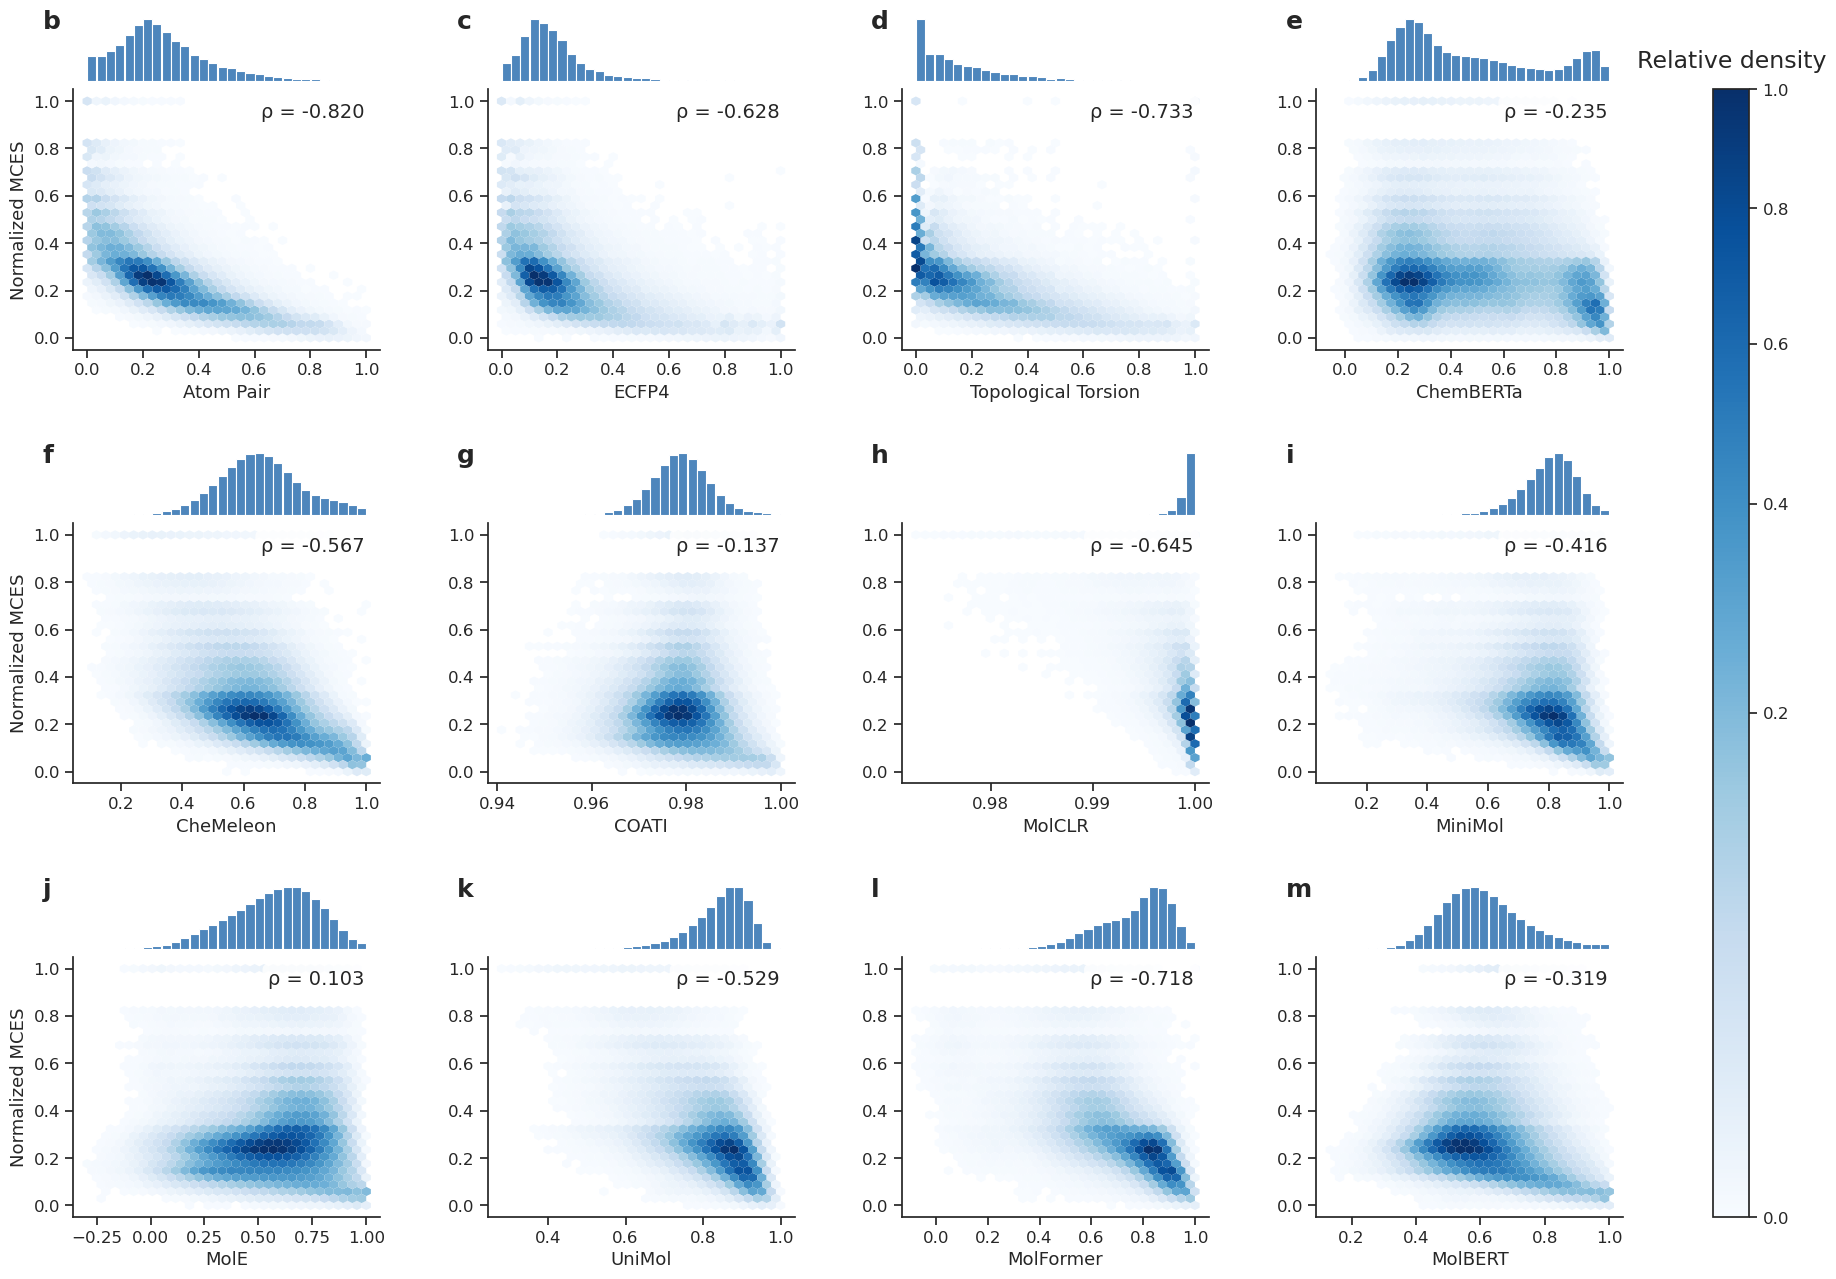

In [ ]:
# ---------------------------------------------------------
# Generate figure
# ---------------------------------------------------------

plot_grid(
    files,
    mces_norm,
    censored,
    ncols=4,
    vertical_gap=0.30,
    out_files=[
        "mces_similarity_grid.pdf",
        "mces_similarity_grid.svg",
    ],
    rasterize_hex=True,
    spearman_fontsize=14,
    tick_fontsize=12,
    label_fontsize=13,
    panel_label_start="b",
    panel_label_fontsize=18,
    panel_label_x=-0.10,
    panel_label_y=1.10,
    gridsize=30,

    # Smaller = more emphasis on lower-density bins.
    density_gamma=0.5,

    colorbar_label="Relative density",

    colorbar_gap=0.045,

    # Width of the colorbar.
    colorbar_width=0.018,
)